In [7]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

sns.set_style("whitegrid")

# Membaca file dataset CSV yang sudah diunggah
df = pd.read_csv("heart_disease_dataset.csv")
print("Ukuran Dataset:", df.shape)
df.head()

Ukuran Dataset: (500, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,67,1,Non-anginal Pain,150,213,0,ST-T Abnormality,168,1,0.9,Upsloping,0,Normal,0
1,57,0,Non-anginal Pain,126,179,0,ST-T Abnormality,188,0,0.3,Upsloping,3,Normal,0
2,43,1,Asymptomatic,154,285,0,Normal,165,0,1.6,Flat,3,Normal,1
3,71,1,Non-anginal Pain,143,290,0,Normal,155,0,2.3,Upsloping,0,Reversible Defect,1
4,36,0,Atypical Angina,131,201,1,ST-T Abnormality,157,0,0.5,Upsloping,1,Normal,0


Jumlah kolom setelah One-Hot Encoding: 19

Distribusi Kelas Target:
target
1.0    324
0.0    176
Name: count, dtype: int64


/tmp/ipykernel_12920/2105574703.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="target", data=df_encoded, palette="Set2")


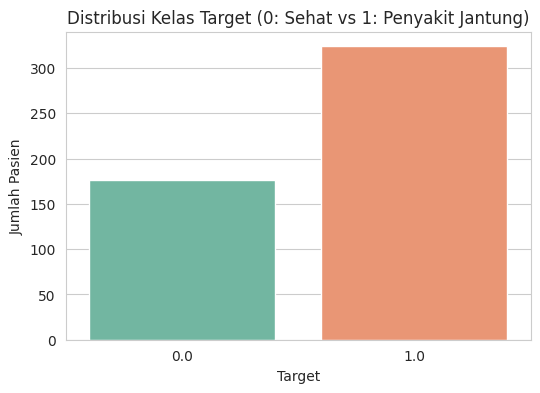

Data Training: 400 sampel | Data Testing: 100 sampel


In [8]:
# 1. Encoding Fitur Kategorikal (Teks -> Numerik 0/1)
categorical_cols = ["cp", "restecg", "slope", "thal"]
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True).astype(
    float
)

print("Jumlah kolom setelah One-Hot Encoding:", df_encoded.shape[1])

# 2. Analisis Ketidakseimbangan Kelas (Class Imbalance)
class_counts = df_encoded["target"].value_counts()
print("\nDistribusi Kelas Target:")
print(class_counts)

plt.figure(figsize=(6, 4))
sns.countplot(x="target", data=df_encoded, palette="Set2")
plt.title("Distribusi Kelas Target (0: Sehat vs 1: Penyakit Jantung)")
plt.xlabel("Target")
plt.ylabel("Jumlah Pasien")
plt.show()

# 3. Split Data (80% Training, 20% Testing)
X = df_encoded.drop(columns=["target"])
y = df_encoded["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(
    f"Data Training: {X_train.shape[0]} sampel | Data Testing:"
    f" {X_test.shape[0]} sampel"
)

Distribusi Kelas Target:
 target
1.0    324
0.0    176
Name: count, dtype: int64


/tmp/ipykernel_12920/4193621.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="target", data=df_encoded, palette="Set2")


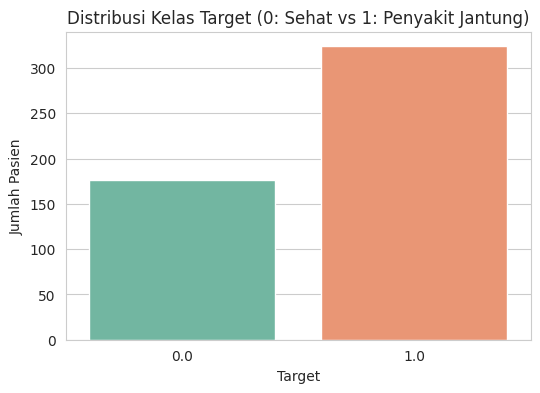

n_estimators =  10 | Test Acc: 0.8000
n_estimators =  50 | Test Acc: 0.7800
n_estimators = 100 | Test Acc: 0.7800
n_estimators = 200 | Test Acc: 0.7800
n_estimators = 500 | Test Acc: 0.7700


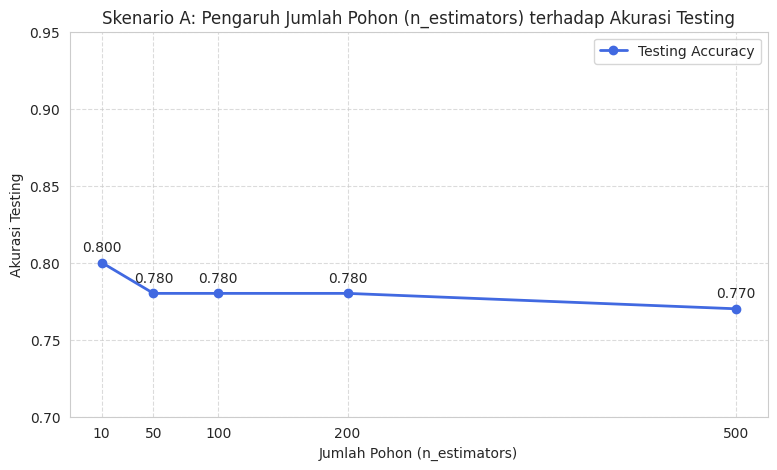


>>> n_estimators terbaik: 10
max_depth = None | Train Acc: 0.9900 | Test Acc: 0.8000
max_depth = 3    | Train Acc: 0.7950 | Test Acc: 0.7200
max_depth = 5    | Train Acc: 0.8950 | Test Acc: 0.7700
max_depth = 10   | Train Acc: 0.9900 | Test Acc: 0.7900
max_depth = 20   | Train Acc: 0.9900 | Test Acc: 0.8000


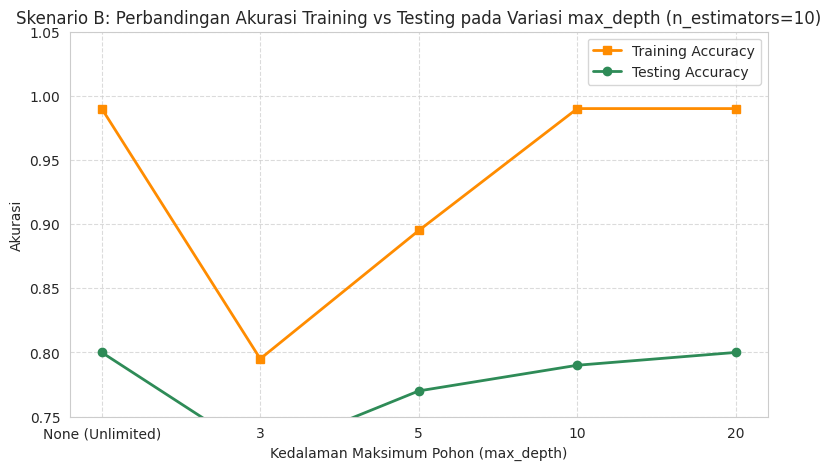


>>> Konfigurasi Terbaik: n_estimators=10, max_depth=None


/tmp/ipykernel_12920/4193621.py:132: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


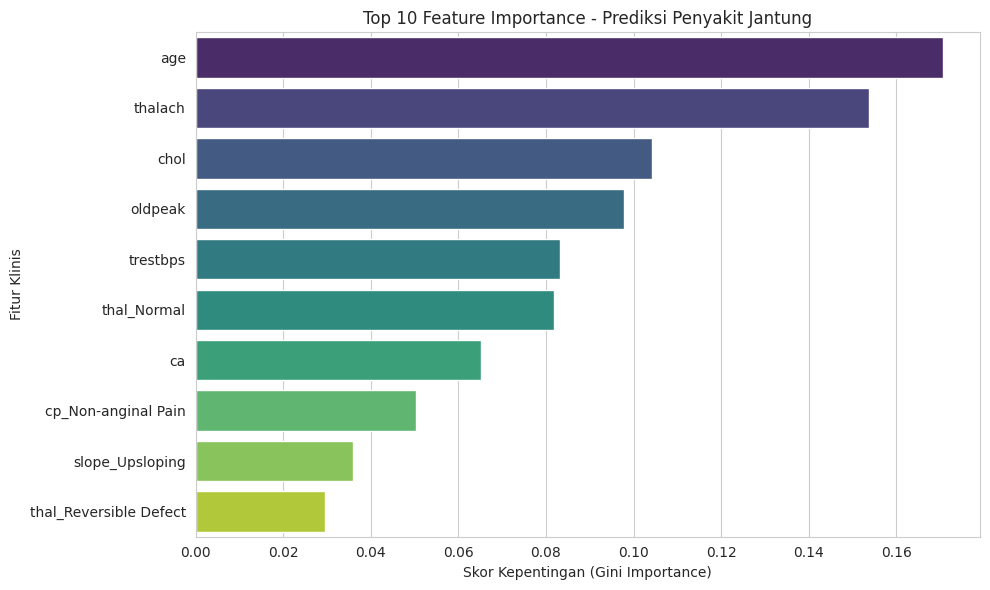


=== EVALUASI MODEL TERBAIK ===
Akurasi Testing : 0.8000

                      precision    recall  f1-score   support

           Sehat (0)       0.73      0.69      0.71        35
Penyakit Jantung (1)       0.84      0.86      0.85        65

            accuracy                           0.80       100
           macro avg       0.78      0.77      0.78       100
        weighted avg       0.80      0.80      0.80       100



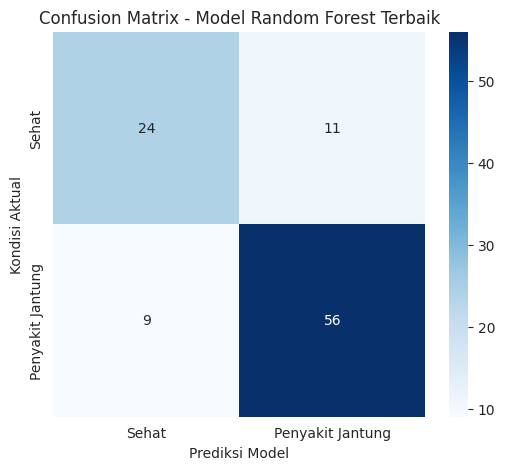

SUKSES! File 'rf_heart_model.pkl' dan 'model_columns.pkl' siap diunduh.


In [10]:
# === SEL 2: PREPROCESSING & SPLIT DATA ===
categorical_cols = ["cp", "restecg", "slope", "thal"]
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True).astype(
    float
)

class_counts = df_encoded["target"].value_counts()
print("Distribusi Kelas Target:\n", class_counts)

plt.figure(figsize=(6, 4))
sns.countplot(x="target", data=df_encoded, palette="Set2")
plt.title("Distribusi Kelas Target (0: Sehat vs 1: Penyakit Jantung)")
plt.xlabel("Target")
plt.ylabel("Jumlah Pasien")
plt.show()

X = df_encoded.drop(columns=["target"])
y = df_encoded["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# === SEL 3: SKENARIO A (n_estimators) ===
n_estimators_list = [10, 50, 100, 200, 500]
test_accuracies_A = []

for n in n_estimators_list:
  rf = RandomForestClassifier(n_estimators=n, random_state=42)
  rf.fit(X_train, y_train)
  test_acc = accuracy_score(y_test, rf.predict(X_test))
  test_accuracies_A.append(test_acc)
  print(f"n_estimators = {n:3d} | Test Acc: {test_acc:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(
    n_estimators_list,
    test_accuracies_A,
    marker="o",
    linewidth=2,
    color="royalblue",
    label="Testing Accuracy",
)
for i, txt in enumerate(test_accuracies_A):
  plt.annotate(
      f"{txt:.3f}",
      (n_estimators_list[i], test_accuracies_A[i]),
      textcoords="offset points",
      xytext=(0, 8),
      ha="center",
  )
plt.title("Skenario A: Pengaruh Jumlah Pohon (n_estimators) terhadap Akurasi Testing")
plt.xlabel("Jumlah Pohon (n_estimators)")
plt.ylabel("Akurasi Testing")
plt.xticks(n_estimators_list)
plt.ylim(0.70, 0.95)
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend()
plt.show()

best_n_estimators = n_estimators_list[np.argmax(test_accuracies_A)]
print(f"\n>>> n_estimators terbaik: {best_n_estimators}")

# === SEL 4: SKENARIO B (max_depth) ===
max_depth_list = [None, 3, 5, 10, 20]
depth_labels = ["None (Unlimited)", "3", "5", "10", "20"]
train_accuracies_B = []
test_accuracies_B = []

for depth in max_depth_list:
  rf = RandomForestClassifier(
      n_estimators=best_n_estimators, max_depth=depth, random_state=42
  )
  rf.fit(X_train, y_train)
  train_acc = accuracy_score(y_train, rf.predict(X_train))
  test_acc = accuracy_score(y_test, rf.predict(X_test))
  train_accuracies_B.append(train_acc)
  test_accuracies_B.append(test_acc)
  print(
      f"max_depth = {str(depth):4s} | Train Acc: {train_acc:.4f} | Test Acc:"
      f" {test_acc:.4f}"
  )

plt.figure(figsize=(9, 5))
plt.plot(
    depth_labels,
    train_accuracies_B,
    marker="s",
    linewidth=2,
    color="darkorange",
    label="Training Accuracy",
)
plt.plot(
    depth_labels,
    test_accuracies_B,
    marker="o",
    linewidth=2,
    color="seagreen",
    label="Testing Accuracy",
)
plt.title(
    "Skenario B: Perbandingan Akurasi Training vs Testing pada Variasi"
    f" max_depth (n_estimators={best_n_estimators})"
)
plt.xlabel("Kedalaman Maksimum Pohon (max_depth)")
plt.ylabel("Akurasi")
plt.ylim(0.75, 1.05)
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend()
plt.show()

best_max_depth = max_depth_list[np.argmax(test_accuracies_B)]
print(
    f"\n>>> Konfigurasi Terbaik: n_estimators={best_n_estimators},"
    f" max_depth={best_max_depth}"
)

# === SEL 5: FEATURE IMPORTANCE ===
best_model = RandomForestClassifier(
    n_estimators=best_n_estimators, max_depth=best_max_depth, random_state=42
)
best_model.fit(X_train, y_train)

fi_df = (
    pd.DataFrame(
        {"Feature": X.columns, "Importance": best_model.feature_importances_}
    )
    .sort_values(by="Importance", ascending=False)
    .reset_index(drop=True)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x="Importance", y="Feature", data=fi_df.head(10), palette="viridis"
)
plt.title("Top 10 Feature Importance - Prediksi Penyakit Jantung")
plt.xlabel("Skor Kepentingan (Gini Importance)")
plt.ylabel("Fitur Klinis")
plt.tight_layout()
plt.show()

# === SEL 6: EVALUASI AKHIR & SIMPAN MODEL (.pkl) ===
y_pred_final = best_model.predict(X_test)
print("\n=== EVALUASI MODEL TERBAIK ===")
print(f"Akurasi Testing : {accuracy_score(y_test, y_pred_final):.4f}\n")
print(
    classification_report(
        y_test, y_pred_final, target_names=["Sehat (0)", "Penyakit Jantung (1)"]
    )
)

cm = confusion_matrix(y_test, y_pred_final)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Sehat", "Penyakit Jantung"],
    yticklabels=["Sehat", "Penyakit Jantung"],
)
plt.title("Confusion Matrix - Model Random Forest Terbaik")
plt.xlabel("Prediksi Model")
plt.ylabel("Kondisi Aktual")
plt.show()

joblib.dump(best_model, "rf_heart_model.pkl")
joblib.dump(list(X.columns), "model_columns.pkl")
print("SUKSES! File 'rf_heart_model.pkl' dan 'model_columns.pkl' siap diunduh.")